<a href="https://colab.research.google.com/github/Namita-Muduli/Recommendation-System/blob/main/Base_Paper_Final_Code.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
!pip -q install shap lime imbalanced-learn xgboost
from google.colab import drive
drive.mount('/content/drive')
!mkdir -p /content/OULAD/OULAD
!cp /content/drive/MyDrive/OULAD/OULAD/*.csv /content/OULAD/OULAD/
!ls -lh /content/OULAD/OULAD

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
total 443M
-rw------- 1 root root 8.1K Nov 17 06:33 assessments.csv
-rw------- 1 root root  526 Nov 17 06:33 courses.csv
-rw------- 1 root root 5.5M Nov 17 06:33 studentAssessment.csv
-rw------- 1 root root 3.4M Nov 17 06:33 studentInfo.csv
-rw------- 1 root root 1.1M Nov 17 06:33 studentRegistration.csv
-rw------- 1 root root 433M Nov 17 06:33 studentVle.csv
-rw------- 1 root root 255K Nov 17 06:33 vle.csv


In [ ]:
import os
print("Working folder:", os.getcwd())
!ls -lh /content
!ls -lh /content/import os
print("Working folder:", os.getcwd())
!ls -lh /content
!ls -lh /content/OULAD/OULAD

Working folder: /content
total 12K
drwx------ 5 root root 4.0K Nov 17 05:29 drive
drwxr-xr-x 3 root root 4.0K Nov 17 05:29 OULAD
-rw-r--r-- 1 root root    0 Nov 17 05:29 oulad.zip
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data
ls: cannot access '/content/import': No such file or directory
ls: cannot access 'os': No such file or directory
Working folder: /content
total 12K
drwx------ 5 root root 4.0K Nov 17 05:29 drive
drwxr-xr-x 3 root root 4.0K Nov 17 05:29 OULAD
-rw-r--r-- 1 root root    0 Nov 17 05:29 oulad.zip
drwxr-xr-x 1 root root 4.0K Oct 26 22:18 sample_data
total 443M
-rw------- 1 root root 8.1K Nov 17 06:33 assessments.csv
-rw------- 1 root root  526 Nov 17 06:33 courses.csv
-rw------- 1 root root 5.5M Nov 17 06:33 studentAssessment.csv
-rw------- 1 root root 3.4M Nov 17 06:33 studentInfo.csv
-rw------- 1 root root 1.1M Nov 17 06:33 studentRegistration.csv
-rw------- 1 root root 433M Nov 17 06:33 studentVle.csv
-rw------- 1 root root 255K Nov 17 06:33 vle.csv


In [ ]:
!pip -q install shap lime imbalanced-learn xgboost
!wget -q --show-progress -O oulad.zip http://schools.stem.open.ac.uk/cdn/files/anonymisedData.zip
!unzip -o -j -q oulad.zip -d .
!ls -lh *.csv

[oulad.zip]
  End-of-central-directory signature not found.  Either this file is not
  a zipfile, or it constitutes one disk of a multi-part archive.  In the
  latter case the central directory and zipfile comment will be found on
  the last disk(s) of this archive.
unzip:  cannot find zipfile directory in one of oulad.zip or
        oulad.zip.zip, and cannot find oulad.zip.ZIP, period.
ls: cannot access '*.csv': No such file or directory


In [ ]:
import sys, numpy as np, pandas as pd
print("Python:", sys.executable)
print("NumPy:", np.__version__)
print("pandas:", pd.__version__)


Python: /usr/bin/python3
NumPy: 2.4.6
pandas: 2.2.3


In [ ]:
# ============================================================
# 1. Imports & Global Config
# ============================================================

import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    accuracy_score, f1_score, roc_auc_score,
    classification_report, confusion_matrix, RocCurveDisplay
)
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.neural_network import MLPClassifier

from xgboost import XGBClassifier

from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline as ImbPipeline

import shap
from lime.lime_tabular import LimeTabularExplainer

import warnings
warnings.filterwarnings("ignore")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

plt.rcParams["figure.figsize"] = (8, 5)
plt.rcParams["axes.grid"] = True

print("Imports and config loaded.")


Imports and config loaded.


In [ ]:
# ============================================================
# 2. Load OULAD CSV Files
#    Put all 7 CSVs in the same folder as this notebook
#    or change DATA_DIR accordingly.
# ============================================================

DATA_DIR = "/content/OULAD/OULAD"  # "." means current folder; change if needed

paths = {
    "assessments":         os.path.join(DATA_DIR, "assessments.csv"),
    "courses":             os.path.join(DATA_DIR, "courses.csv"),
    "vle":                 os.path.join(DATA_DIR, "vle.csv"),
    "studentRegistration": os.path.join(DATA_DIR, "studentRegistration.csv"),
    "studentInfo":         os.path.join(DATA_DIR, "studentInfo.csv"),
    "studentAssessment":   os.path.join(DATA_DIR, "studentAssessment.csv"),
    "studentVle":          os.path.join(DATA_DIR, "studentVle.csv"),
}

for name, p in paths.items():
    if not os.path.exists(p):
        raise FileNotFoundError(f"{name} file not found at: {p}")

df_assessments         = pd.read_csv(paths["assessments"])
df_courses             = pd.read_csv(paths["courses"])
df_vle                 = pd.read_csv(paths["vle"])
df_student_registration= pd.read_csv(paths["studentRegistration"])
df_student_info        = pd.read_csv(paths["studentInfo"])
df_student_assessment  = pd.read_csv(paths["studentAssessment"])
df_student_vle         = pd.read_csv(paths["studentVle"])

print("All CSV files loaded.")
print("assessments:", df_assessments.shape)
print("courses:", df_courses.shape)
print("vle:", df_vle.shape)
print("studentRegistration:", df_student_registration.shape)
print("studentInfo:", df_student_info.shape)
print("studentAssessment:", df_student_assessment.shape)
print("studentVle:", df_student_vle.shape)


All CSV files loaded.
assessments: (206, 6)
courses: (22, 3)
vle: (6364, 6)
studentRegistration: (32593, 5)
studentInfo: (32593, 12)
studentAssessment: (173912, 5)
studentVle: (10655280, 6)


In [ ]:
# ============================================================
# 3. Base Student Dataset + Target Variable
#    Merge studentRegistration + studentInfo + courses
# ============================================================

# Merge registration with student info
df_students = pd.merge(
    df_student_registration,
    df_student_info,
    on=["code_module", "code_presentation", "id_student"],
    how="inner"
)

# Merge course length
df_students = pd.merge(
    df_students,
    df_courses,
    on=["code_module", "code_presentation"],
    how="left"
)

print("Base student-level dataset shape:", df_students.shape)

# Create binary target: passed (Pass/Distinction = 1, Fail/Withdrawn = 0)
df_students["passed"] = df_students["final_result"].apply(
    lambda x: 1 if x in ["Pass", "Distinction"] else 0
)

print(df_students["final_result"].value_counts())
print("\nTarget distribution (Successful):")
print(df_students["passed"].value_counts(normalize=True))

# Optional: basic time-based feature
# If date_unregistration is NaN, assume student remained to end of module
df_students["date_unregistration_filled"] = df_students["date_unregistration"].fillna(
    df_students["module_presentation_length"]
)
df_students["enrolment_length"] = (
    df_students["date_unregistration_filled"] - df_students["date_registration"]
)


Base student-level dataset shape: (32593, 15)
final_result
Pass           12361
Withdrawn      10156
Fail            7052
Distinction     3024
Name: count, dtype: int64

Target distribution (Successful):
passed
0    0.527966
1    0.472034
Name: proportion, dtype: float64


In [ ]:
# ============================================================
# 4. Assessment Features (Aggregated per Student-Module)
# ------------------------------------------------------------
# RECONSTRUCTED CELL. In the shared notebook this cell was empty and
# `group_cols` / `df_agg_assess` were never defined, so cell 6 and 7
# fail with NameError. This code rebuilds the same 14 columns that the
# author's saved output shows (shape (25843, 14)).
# ============================================================

group_cols = ["id_student", "code_module", "code_presentation"]

df_assess_merged = pd.merge(
    df_student_assessment,
    df_assessments,
    on="id_assessment",
    how="left"
)
df_assess_merged["weighted_score"] = df_assess_merged["score"] * df_assess_merged["weight"]

df_agg_assess = df_assess_merged.groupby(group_cols).agg(
    num_assessments=("id_assessment", "count"),
    mean_score=("score", "mean"),
    max_score=("score", "max"),
    min_score=("score", "min"),
    std_score=("score", "std"),
    total_weight=("weight", "sum"),
    total_weighted_score=("weighted_score", "sum")
).reset_index()

df_agg_assess["weighted_avg_score"] = (
    df_agg_assess["total_weighted_score"] / df_agg_assess["total_weight"]
)

# number of TMA / CMA / Exam submissions per student-module
type_counts = df_assess_merged.pivot_table(
    index=group_cols,
    columns="assessment_type",
    values="id_assessment",
    aggfunc="count",
    fill_value=0
)
type_counts = type_counts.reindex(columns=["TMA", "CMA", "Exam"], fill_value=0)
type_counts.columns = [f"num_{c}" for c in type_counts.columns]
type_counts = type_counts.reset_index()

df_agg_assess = pd.merge(df_agg_assess, type_counts, on=group_cols, how="left")

print("Assessment features shape:", df_agg_assess.shape)
print("(The author's saved output for this cell was: (25843, 14))")
df_agg_assess.head()


Assessment features shape: (25843, 14)
(The author's saved output for this cell was: (25843, 14))


,id_student,code_module,code_presentation,num_assessments,mean_score,max_score,min_score,std_score,total_weight,total_weighted_score,weighted_avg_score,num_TMA,num_CMA,num_Exam
0,6516,AAA,2014J,5,61.800000,77.0,48.0,10.329569,100.0,6350.0,63.50,5,0,0
1,8462,DDD,2013J,3,87.666667,93.0,83.0,5.033223,40.0,3490.0,87.25,3,0,0
2,8462,DDD,2014J,4,86.500000,93.0,83.0,4.725816,50.0,4300.0,86.00,4,0,0
3,11391,AAA,2013J,5,82.000000,85.0,78.0,3.082207,100.0,8240.0,82.40,5,0,0
4,23629,BBB,2013B,4,82.500000,100.0,63.0,20.273135,25.0,1669.0,66.76,2,2,0


In [ ]:
# ============================================================
# 5. VLE Features (Aggregated per Student-Module)
# ============================================================

# Merge studentVle with vle to get activity_type
df_svle = pd.merge(
    df_student_vle,
    df_vle[["id_site", "activity_type"]],
    on="id_site",
    how="left"
)

# Aggregate main VLE usage features
df_agg_vle = df_svle.groupby(group_cols).agg(
    total_clicks=("sum_click", "sum"),
    days_active=("date", "nunique"),
    num_resources=("id_site", "nunique")
).reset_index()

# Optional: clicks by activity_type (pivot)
activity_clicks = df_svle.pivot_table(
    index=group_cols,
    columns="activity_type",
    values="sum_click",
    aggfunc="sum",
    fill_value=0
)

activity_clicks.columns = [f"clicks_{c}" for c in activity_clicks.columns]
activity_clicks = activity_clicks.reset_index()

# Merge aggregated VLE features
df_agg_vle = pd.merge(df_agg_vle, activity_clicks, on=group_cols, how="left")

print("VLE features shape:", df_agg_vle.shape)
df_agg_vle.head()


VLE features shape: (29228, 26)


,id_student,code_module,code_presentation,total_clicks,days_active,num_resources,clicks_dataplus,clicks_dualpane,clicks_externalquiz,clicks_folder,...,clicks_ouelluminate,clicks_ouwiki,clicks_page,clicks_questionnaire,clicks_quiz,clicks_repeatactivity,clicks_resource,clicks_sharedsubpage,clicks_subpage,clicks_url
0,6516,AAA,2014J,2791,159,84,21,0,0,0,...,0,0,0,0,0,0,31,0,143,143
1,8462,DDD,2013J,646,56,125,0,0,12,0,...,0,18,0,0,0,0,70,0,227,23
2,8462,DDD,2014J,10,1,3,0,0,0,0,...,0,0,0,0,0,0,0,0,0,0
3,11391,AAA,2013J,934,40,55,0,0,0,0,...,0,0,0,0,0,0,13,0,32,5
4,23629,BBB,2013B,161,16,11,0,0,0,0,...,0,0,0,0,31,0,2,0,5,0


In [ ]:
# ============================================================
# 6. Build Final Modeling Dataset
#    Merge base student info + assessment + vle features
# ============================================================

df_final = df_students.merge(
    df_agg_assess,
    on=["id_student", "code_module", "code_presentation"],
    how="left"
)

df_final = df_final.merge(
    df_agg_vle,
    on=["id_student", "code_module", "code_presentation"],
    how="left"
)

print("Final dataset shape (before cleaning):", df_final.shape)

# Basic missing value handling:
# numeric feature NaNs -> 0
numeric_cols = df_final.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
# but keep target separate
numeric_cols = [c for c in numeric_cols if c not in ["passed"]]

df_final[numeric_cols] = df_final[numeric_cols].fillna(0)

# Some date columns may still be NaN, handle them safely
for col in ["date_unregistration", "date_unregistration_filled", "enrolment_length"]:
    if col in df_final.columns:
        df_final[col] = df_final[col].fillna(0)

print("Final dataset after basic NA handling:")
df_final.info()


Final dataset shape (before cleaning): (32593, 52)
Final dataset after basic NA handling:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 32593 entries, 0 to 32592
Data columns (total 52 columns):
 #   Column                      Non-Null Count  Dtype  
---  ------                      --------------  -----  
 0   code_module                 32593 non-null  object 
 1   code_presentation           32593 non-null  object 
 2   id_student                  32593 non-null  int64  
 3   date_registration           32593 non-null  float64
 4   date_unregistration         32593 non-null  float64
 5   gender                      32593 non-null  object 
 6   region                      32593 non-null  object 
 7   highest_education           32593 non-null  object 
 8   imd_band                    31482 non-null  object 
 9   age_band                    32593 non-null  object 
 10  num_of_prev_attempts        32593 non-null  int64  
 11  studied_credits             32593 non-null  int64  
 12

In [ ]:
# ============================================================
# 7. Select Features & Target for Modeling
# ============================================================

# Target:
TARGET_COL = "passed"

# Columns to drop from features (IDs and strong leak targets)
drop_cols = [
    "passed",
    "final_result",
    "id_student",
    # If you think some of these leak too much future info, you can also drop them:
    # "date_unregistration", "date_unregistration_filled"
]

X = df_final.drop(columns=[c for c in drop_cols if c in df_final.columns])
y = df_final[TARGET_COL].astype(int)

print("X shape:", X.shape)
print("y shape:", y.shape)

# Identify numeric and categorical feature columns
numeric_features = X.select_dtypes(include=["int64", "float64", "int32", "float32"]).columns.tolist()
categorical_features = X.select_dtypes(include=["object", "category", "bool"]).columns.tolist()

print("Numeric features:", numeric_features)
print("Categorical features:", categorical_features)

# Train-Test Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    stratify=y,
    random_state=RANDOM_STATE
)

print("Train:", X_train.shape, "Test:", X_test.shape)


X shape: (32593, 49)
y shape: (32593,)
Numeric features: ['date_registration', 'date_unregistration', 'num_of_prev_attempts', 'studied_credits', 'module_presentation_length', 'date_unregistration_filled', 'enrolment_length', 'num_assessments', 'mean_score', 'max_score', 'min_score', 'std_score', 'total_weight', 'total_weighted_score', 'weighted_avg_score', 'num_TMA', 'num_CMA', 'num_Exam', 'total_clicks', 'days_active', 'num_resources', 'clicks_dataplus', 'clicks_dualpane', 'clicks_externalquiz', 'clicks_folder', 'clicks_forumng', 'clicks_glossary', 'clicks_homepage', 'clicks_htmlactivity', 'clicks_oucollaborate', 'clicks_oucontent', 'clicks_ouelluminate', 'clicks_ouwiki', 'clicks_page', 'clicks_questionnaire', 'clicks_quiz', 'clicks_repeatactivity', 'clicks_resource', 'clicks_sharedsubpage', 'clicks_subpage', 'clicks_url']
Categorical features: ['code_module', 'code_presentation', 'gender', 'region', 'highest_education', 'imd_band', 'age_band', 'disability']
Train: (26074, 49) Test: (

In [ ]:
# ============================================================
# 8. Preprocessing Pipeline (ColumnTransformer)
# ============================================================

numeric_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("onehot", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer(
    transformers=[
        ("num", numeric_transformer, numeric_features),
        ("cat", categorical_transformer, categorical_features)
    ]
)

print("Preprocessor defined.")


Preprocessor defined.


In [ ]:
# ============================================================
# 9. Define Models & Cross-Validation with SMOTE
# ============================================================

models = {
    "LogisticRegression": LogisticRegression(
        max_iter=500,
        solver="lbfgs",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        max_iter=300,
        random_state=RANDOM_STATE
    )
}

cv_results = []
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

for name, clf in models.items():
    print(f"\n===== Evaluating {name} =====")

    pipe = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", clf)
    ])

    scores = cross_val_score(
        pipe,
        X_train,
        y_train,
        scoring="roc_auc",
        cv=skf,
        n_jobs=-1
    )

    print("CV ROC-AUC scores:", scores)
    print("Mean ROC-AUC:", scores.mean())

    cv_results.append({
        "model": name,
        "mean_roc_auc": scores.mean(),
        "std_roc_auc": scores.std()
    })

cv_df = pd.DataFrame(cv_results).sort_values(by="mean_roc_auc", ascending=False)
print("\n=== Cross-validation summary ===")
print(cv_df)



===== Evaluating LogisticRegression =====
CV ROC-AUC scores: [0.98573358 0.98172867 0.98303911 0.98601599 0.98411042]
Mean ROC-AUC: 0.9841255544929192

===== Evaluating RandomForest =====
CV ROC-AUC scores: [0.98766517 0.98442095 0.98524865 0.98743937 0.98751434]
Mean ROC-AUC: 0.9864576956652632

===== Evaluating XGBoost =====
CV ROC-AUC scores: [0.98907592 0.98659612 0.98705009 0.98906031 0.98819551]
Mean ROC-AUC: 0.9879955877806917

===== Evaluating MLP =====
CV ROC-AUC scores: [0.98050768 0.97756557 0.97984364 0.98118189 0.97898816]
Mean ROC-AUC: 0.9796173899251972

=== Cross-validation summary ===
                model  mean_roc_auc  std_roc_auc
2             XGBoost      0.987996     0.001019
1        RandomForest      0.986458     0.001353
0  LogisticRegression      0.984126     0.001618
3                 MLP      0.979617     0.001257


In [ ]:
# ============================================================
# 9. Define Models & Cross-Validation with SMOTE + Full Metrics
# ============================================================

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

models = {
    "LogisticRegression": LogisticRegression(
        max_iter=500,
        solver="lbfgs",
        class_weight="balanced",
        random_state=RANDOM_STATE
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        n_jobs=-1,
        random_state=RANDOM_STATE,
        class_weight="balanced_subsample"
    ),
    "XGBoost": XGBClassifier(
        n_estimators=300,
        learning_rate=0.05,
        max_depth=5,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="binary:logistic",
        eval_metric="logloss",
        random_state=RANDOM_STATE,
        n_jobs=-1
    ),
    "MLP": MLPClassifier(
        hidden_layer_sizes=(64, 32),
        activation="relu",
        solver="adam",
        alpha=1e-4,
        max_iter=300,
        random_state=RANDOM_STATE
    )
}

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
metrics_results = []

print("\n================ MODEL EVALUATION (5-FOLD CV) ================\n")

for name, clf in models.items():
    print(f"\n===== Evaluating {name} =====")

    pipe = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", clf)
    ])

    fold_metrics = {
        "model": name,
        "accuracy": [],
        "precision": [],
        "recall": [],
        "f1": [],
        "roc_auc": []
    }

    for train_idx, valid_idx in skf.split(X_train, y_train):
        X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[valid_idx]
        y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[valid_idx]

        pipe.fit(X_tr, y_tr)
        preds = pipe.predict(X_val)
        probs = pipe.predict_proba(X_val)[:, 1]

        fold_metrics["accuracy"].append(accuracy_score(y_val, preds))
        fold_metrics["precision"].append(precision_score(y_val, preds, zero_division=0))
        fold_metrics["recall"].append(recall_score(y_val, preds, zero_division=0))
        fold_metrics["f1"].append(f1_score(y_val, preds, zero_division=0))
        fold_metrics["roc_auc"].append(roc_auc_score(y_val, probs))

    # Store mean values
    metrics_results.append({
        "Model": name,
        "Accuracy": np.mean(fold_metrics["accuracy"]),
        "Precision": np.mean(fold_metrics["precision"]),
        "Recall": np.mean(fold_metrics["recall"]),
        "F1-Score": np.mean(fold_metrics["f1"]),
        "ROC-AUC": np.mean(fold_metrics["roc_auc"])
    })

# Convert to DataFrame
metrics_df = pd.DataFrame(metrics_results)
metrics_df = metrics_df.sort_values(by="ROC-AUC", ascending=False)

print("\n================ 5-FOLD CROSS-VALIDATION METRICS ================\n")
print(metrics_df)



================ MODEL EVALUATION (5-FOLD CV) ================


===== Evaluating LogisticRegression =====

===== Evaluating RandomForest =====

===== Evaluating XGBoost =====

===== Evaluating MLP =====

================ 5-FOLD CROSS-VALIDATION METRICS ================

                Model  Accuracy  Precision    Recall  F1-Score   ROC-AUC
2             XGBoost  0.951331   0.926215  0.974569  0.949764  0.987996
1        RandomForest  0.949605   0.922610  0.975057  0.948096  0.986458
0  LogisticRegression  0.942586   0.916440  0.966526  0.940804  0.984126
3                 MLP  0.932231   0.923776  0.933539  0.928579  0.979617



Best model based on CV ROC-AUC: XGBoost

=== Test Performance ===
Accuracy : 0.9529068875594416
F1-score: 0.9513855898653999
ROC-AUC : 0.9882863184085708

Classification report:
              precision    recall  f1-score   support

           0       0.98      0.93      0.95      3442
           1       0.93      0.98      0.95      3077

    accuracy                           0.95      6519
   macro avg       0.95      0.95      0.95      6519
weighted avg       0.95      0.95      0.95      6519

Confusion matrix:
 [[3208  234]
 [  73 3004]]


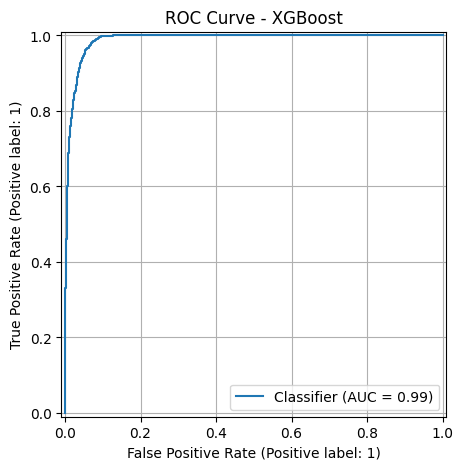

In [ ]:
# ============================================================
# 10. Fit Best Model on Full Training Data & Evaluate on Test
# ============================================================

best_model_name = cv_df.iloc[0]["model"]
print(f"\nBest model based on CV ROC-AUC: {best_model_name}")

best_clf = models[best_model_name]

best_pipeline = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", best_clf)
])

best_pipeline.fit(X_train, y_train)

y_pred = best_pipeline.predict(X_test)
y_proba = best_pipeline.predict_proba(X_test)[:, 1]

acc = accuracy_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
roc_auc = roc_auc_score(y_test, y_proba)

print("\n=== Test Performance ===")
print("Accuracy :", acc)
print("F1-score:", f1)
print("ROC-AUC :", roc_auc)

print("\nClassification report:")
print(classification_report(y_test, y_pred))

cm = confusion_matrix(y_test, y_pred)
print("Confusion matrix:\n", cm)

RocCurveDisplay.from_predictions(y_test, y_proba)
plt.title(f"ROC Curve - {best_model_name}")
plt.show()


In [ ]:
# ============================================================
# 10. Ensemble Learning: Bagging (Decision Tree base)
# ============================================================

from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import BaggingClassifier
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score
)

bagging_clf = BaggingClassifier(
    estimator=DecisionTreeClassifier(
        max_depth=None,
        min_samples_split=2,
        min_samples_leaf=1,
        random_state=RANDOM_STATE
    ),
    n_estimators=100,
    max_samples=0.8,
    max_features=1.0,
    bootstrap=True,
    n_jobs=-1,
    random_state=RANDOM_STATE
)

bagging_pipe = ImbPipeline(steps=[
    ("preprocess", preprocessor),
    ("smote", SMOTE(random_state=RANDOM_STATE)),
    ("model", bagging_clf)
])

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

bagging_metrics = {
    "accuracy": [],
    "precision": [],
    "recall": [],
    "f1": [],
    "roc_auc": []
}

print("\n===== Bagging (Decision Tree base) — 5-fold CV =====")

for train_idx, val_idx in skf.split(X_train, y_train):
    X_tr, X_val = X_train.iloc[train_idx], X_train.iloc[val_idx]
    y_tr, y_val = y_train.iloc[train_idx], y_train.iloc[val_idx]

    bagging_pipe.fit(X_tr, y_tr)
    preds = bagging_pipe.predict(X_val)
    probs = bagging_pipe.predict_proba(X_val)[:, 1]

    bagging_metrics["accuracy"].append(accuracy_score(y_val, preds))
    bagging_metrics["precision"].append(precision_score(y_val, preds, zero_division=0))
    bagging_metrics["recall"].append(recall_score(y_val, preds, zero_division=0))
    bagging_metrics["f1"].append(f1_score(y_val, preds, zero_division=0))
    bagging_metrics["roc_auc"].append(roc_auc_score(y_val, probs))

print("\nMean CV Accuracy :", np.mean(bagging_metrics['accuracy']))
print("Mean CV Precision:", np.mean(bagging_metrics['precision']))
print("Mean CV Recall   :", np.mean(bagging_metrics['recall']))
print("Mean CV F1-Score :", np.mean(bagging_metrics['f1']))
print("Mean CV ROC-AUC  :", np.mean(bagging_metrics['roc_auc']))

# Fit on full training set and evaluate on test set
bagging_pipe.fit(X_train, y_train)
y_pred_test = bagging_pipe.predict(X_test)
y_prob_test = bagging_pipe.predict_proba(X_test)[:, 1]

print("\n===== Bagging — Test Set Performance =====")
print("Test Accuracy :", accuracy_score(y_test, y_pred_test))
print("Test Precision:", precision_score(y_test, y_pred_test, zero_division=0))
print("Test Recall   :", recall_score(y_test, y_pred_test, zero_division=0))
print("Test F1-Score :", f1_score(y_test, y_pred_test, zero_division=0))
print("Test ROC-AUC  :", roc_auc_score(y_test, y_prob_test))



===== Bagging (Decision Tree base) — 5-fold CV =====

Mean CV Accuracy : 0.9487612339519569
Mean CV Precision: 0.9240634747353529
Mean CV Recall   : 0.9713193734525041
Mean CV F1-Score : 0.9470839282134023
Mean CV ROC-AUC  : 0.9849704612110448

===== Bagging — Test Set Performance =====
Test Accuracy : 0.9504525233931584
Test Precision: 0.927639751552795
Test Recall   : 0.9707507312317192
Test F1-Score : 0.9487057328886771
Test ROC-AUC  : 0.9866474793679257



=== SHAP Analysis (Best Model) ===
Best model: XGBoost
Transformed feature shape: (6519, 87)
Number of feature names: 87


100%|===================| 6492/6519 [01:23<00:00]       

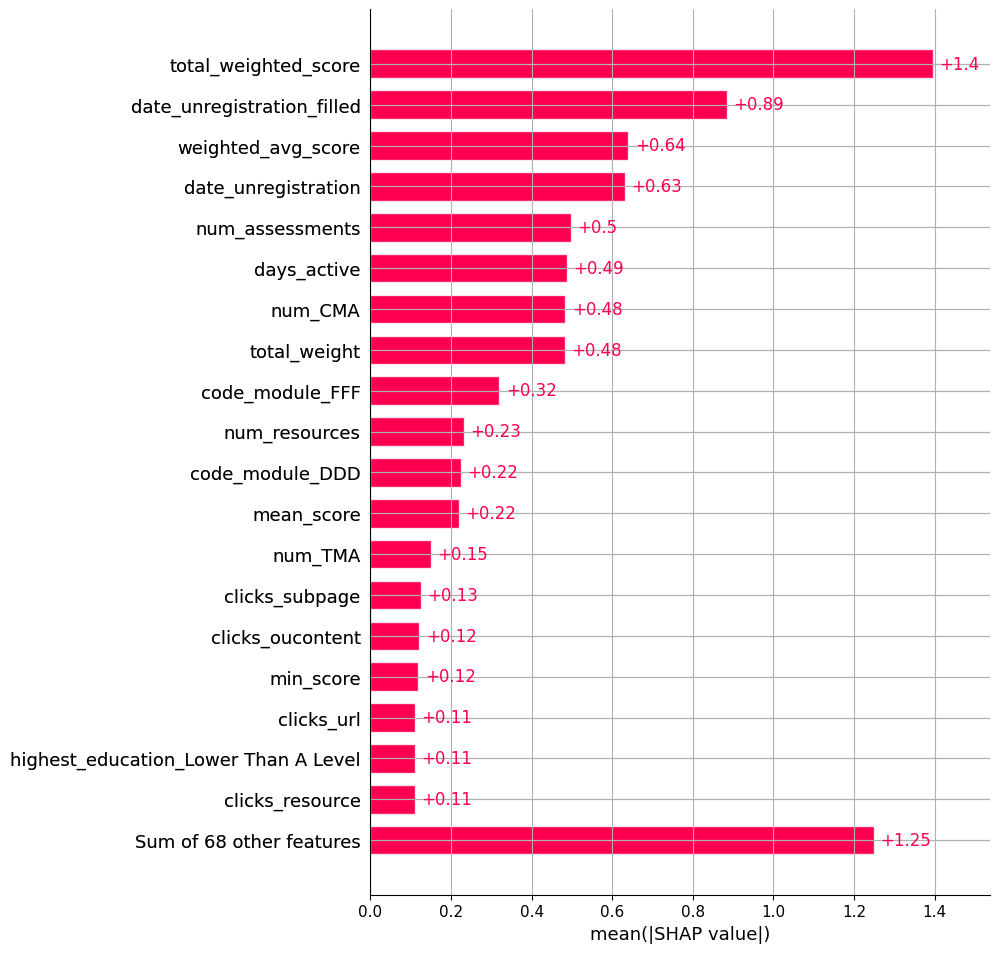

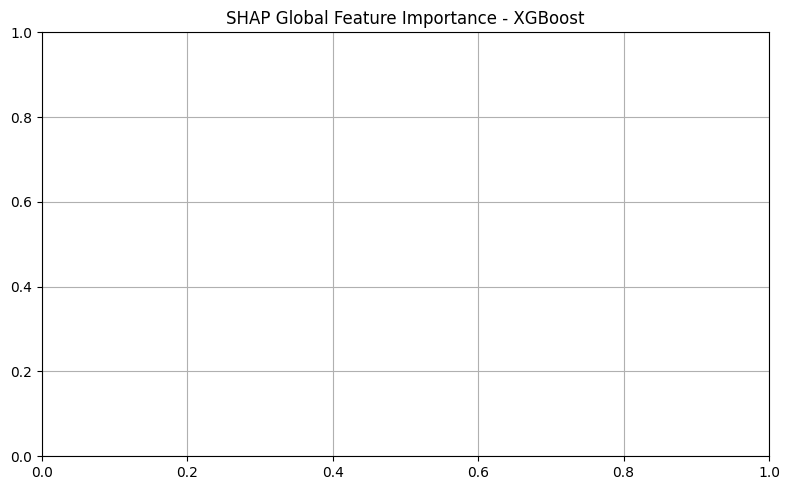

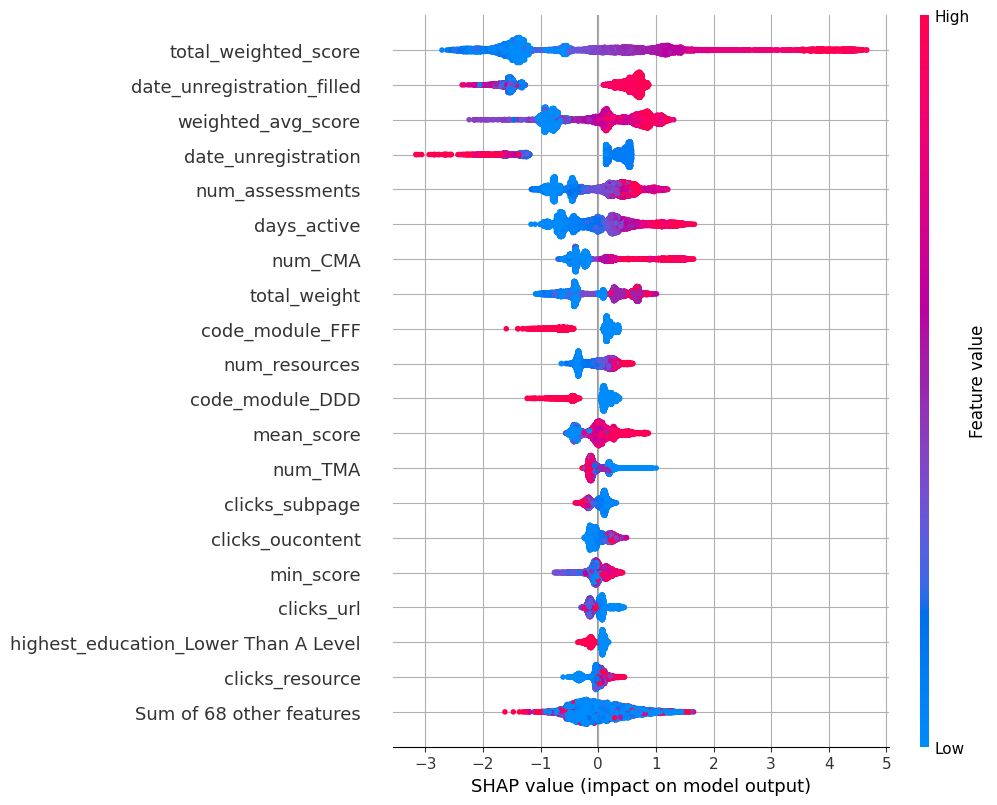

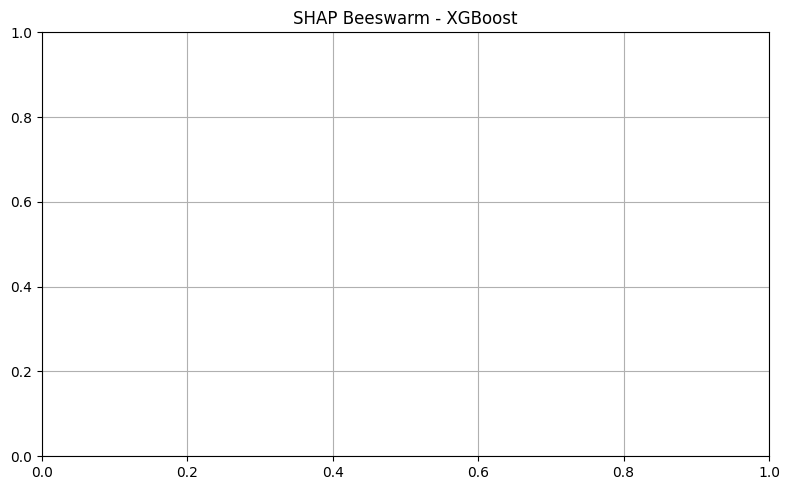


Top features by mean |SHAP|:
 - total_weighted_score
 - date_unregistration_filled
 - weighted_avg_score
 - date_unregistration
 - num_assessments
 - days_active


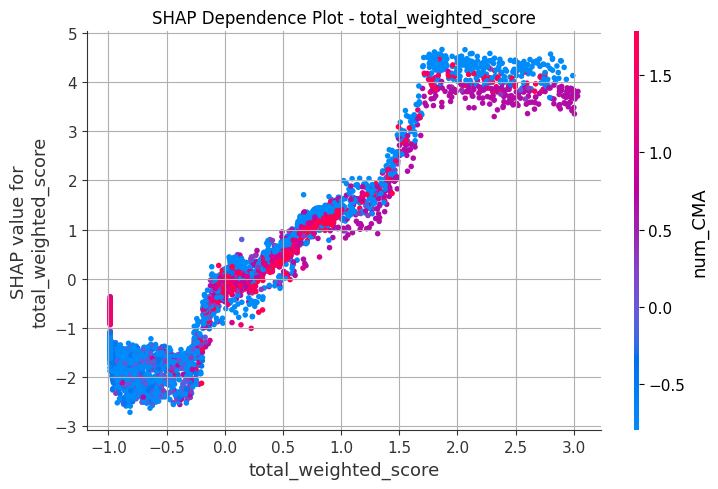

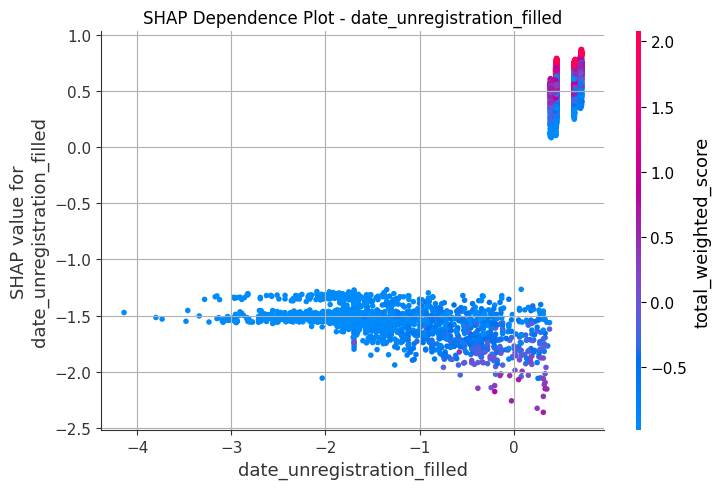

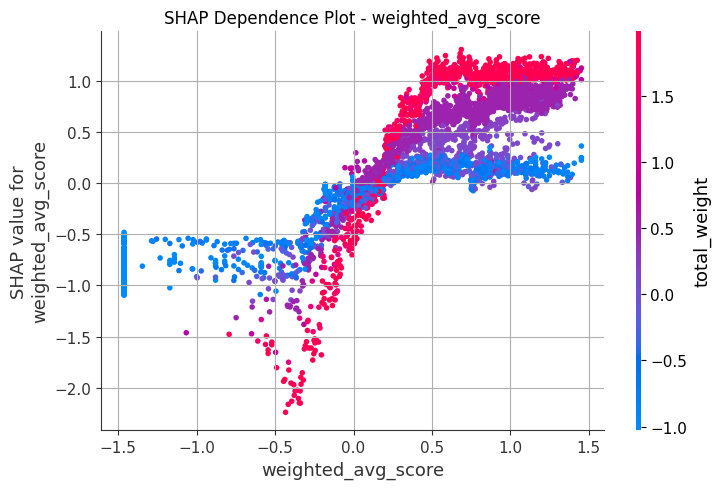

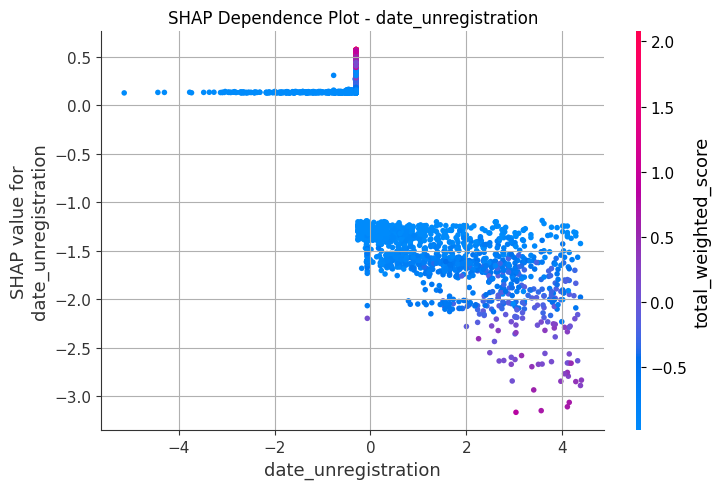

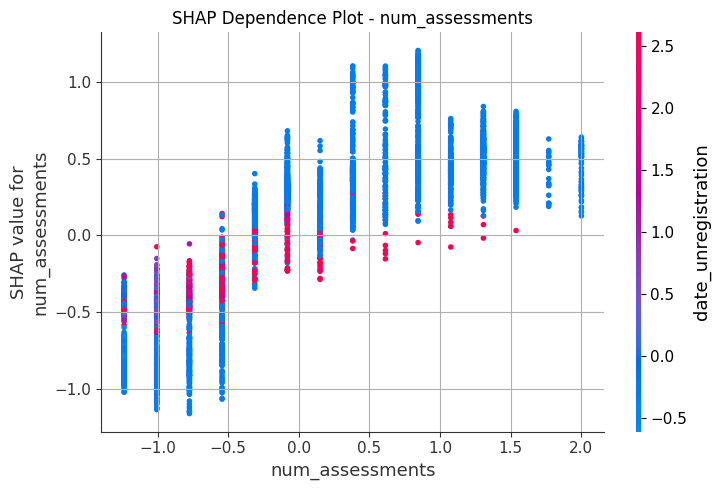

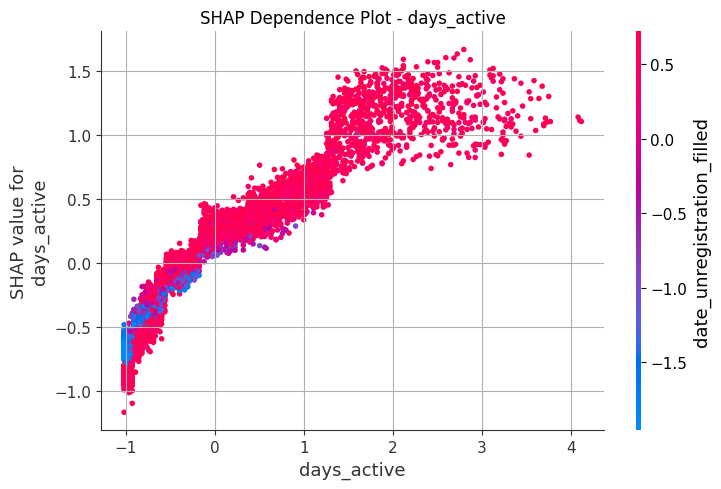

In [ ]:
# ============================================================
# 11. SHAP Interpretability for Best Model
#     (Works for tree + non-tree + ensemble models)
# ============================================================

print("\n=== SHAP Analysis (Best Model) ===")
print("Best model:", best_model_name)

fitted_preprocessor = best_pipeline.named_steps["preprocess"]
fitted_model        = best_pipeline.named_steps["model"]

# -----------------------------
# 1) Transform train / test data
# -----------------------------
X_train_trans = fitted_preprocessor.transform(X_train)
X_test_trans  = fitted_preprocessor.transform(X_test)

# Convert sparse -> dense if needed
if hasattr(X_train_trans, "toarray"):
    X_train_dense = X_train_trans.toarray()
    X_test_dense  = X_test_trans.toarray()
else:
    X_train_dense = X_train_trans
    X_test_dense  = X_test_trans

# -----------------------------
# 2) Build feature names (num + OHE)
# -----------------------------
feature_names_num = numeric_features

if categorical_features:
    ohe = fitted_preprocessor.named_transformers_["cat"]["onehot"]
    feature_names_cat = ohe.get_feature_names_out(categorical_features).tolist()
else:
    feature_names_cat = []

feature_names_all = feature_names_num + feature_names_cat

# Sanitize feature names for XGBoost / SHAP:
# XGBoost does not allow [, ], or < in feature names.
safe_feature_names = [
    str(f).replace("[", "(").replace("]", ")").replace("<", "lt")
    for f in feature_names_all
]

print("Transformed feature shape:", X_test_dense.shape)
print("Number of feature names:", len(safe_feature_names))

# Wrap into DataFrames for SHAP
X_train_shap = pd.DataFrame(X_train_dense, columns=safe_feature_names)
X_test_shap  = pd.DataFrame(X_test_dense,  columns=safe_feature_names)

# -----------------------------
# 3) Create SHAP Explainer
#    (model-agnostic, works for ensembles too)
# -----------------------------
explainer = shap.Explainer(fitted_model, X_train_shap)
shap_values = explainer(X_test_shap)

# -----------------------------
# 4) Global Feature Importance
# -----------------------------
shap.plots.bar(shap_values, max_display=20)
plt.title(f"SHAP Global Feature Importance - {best_model_name}")
plt.tight_layout()
plt.show()

# -----------------------------
# 5) Beeswarm Plot
# -----------------------------
shap.plots.beeswarm(shap_values, max_display=20)
plt.title(f"SHAP Beeswarm - {best_model_name}")
plt.tight_layout()
plt.show()

# -----------------------------
# 6) Top-N features & dependence plots
# -----------------------------
N_TOP = 6
vals = np.abs(shap_values.values).mean(axis=0)
top_idx = np.argsort(vals)[-N_TOP:][::-1]
top_features = [safe_feature_names[i] for i in top_idx]

print("\nTop features by mean |SHAP|:")
for f in top_features:
    print(" -", f)

for feat in top_features:
    shap.dependence_plot(
        feat,
        shap_values.values,
        X_test_shap,
        feature_names=safe_feature_names,
        show=False
    )
    plt.title(f"SHAP Dependence Plot - {feat}")
    plt.tight_layout()
    plt.show()


In [ ]:
# ============================================================
# 12. LIME Interpretability for Best Model
#     (Supports single + ensemble models)
# ============================================================

from lime.lime_tabular import LimeTabularExplainer

print("\n=== LIME Analysis (Best Model) ===")
print("Best model:", best_model_name)

# Use the same categorical features you used in the preprocessor
cat_cols = categorical_features

# 1) Encode categorical features as integers for LIME
cat_to_int = {}
int_to_cat = {}

X_train_lime = X_train.copy()

for col in cat_cols:
    # use strings for safety
    cats = X_train[col].astype(str).unique()
    cats_sorted = sorted(cats)
    map_cat_to_int = {cat: i for i, cat in enumerate(cats_sorted)}
    map_int_to_cat = {i: cat for cat, i in map_cat_to_int.items()}

    cat_to_int[col] = map_cat_to_int
    int_to_cat[col] = map_int_to_cat

    X_train_lime[col] = X_train[col].astype(str).map(map_cat_to_int)

# 2) Categorical indices + names for LIME
categorical_idx = [X_train.columns.get_loc(c) for c in cat_cols]

categorical_names = {
    X_train.columns.get_loc(col): [int_to_cat[col][i] for i in sorted(int_to_cat[col].keys())]
    for col in cat_cols
}

print("Number of features:", X_train.shape[1])
print("Categorical feature count:", len(categorical_idx))

# 3) Build LIME explainer on numeric training data
class_names = ["Not Passed", "Passed"]   # adjust if needed

lime_explainer = LimeTabularExplainer(
    training_data=X_train_lime.values,
    feature_names=X_train.columns.tolist(),
    class_names=class_names,
    categorical_features=categorical_idx,
    categorical_names=categorical_names,
    mode="classification"
)

# 4) Prediction wrapper: decode ints -> original categories, then call pipeline
def pipeline_predict_proba_lime(x):
    """
    x: 2D numpy array with encoded ints in categorical columns.
    Convert back to original categories, then call best_pipeline.predict_proba.
    """
    x_df = pd.DataFrame(x, columns=X_train.columns)

    for col in cat_cols:
        idx_map = int_to_cat[col]
        x_df[col] = x_df[col].round().astype(int).map(idx_map)

    return best_pipeline.predict_proba(x_df)



=== LIME Analysis (Best Model) ===
Best model: XGBoost
Number of features: 49
Categorical feature count: 8



Explaining test instance index: 0
True label     : 0
Predicted label: 0

LIME feature contributions (feature, weight):
  241.00 < date_unregistration_filled <= 268.00 -0.1623
  date_unregistration <= 0.00         -0.1451
  0.00 < total_weighted_score <= 4096.00  0.1308
  clicks_sharedsubpage <= 0.00         0.0748
  0.00 < total_weight <= 72.00         0.0454
  code_module=DDD                      0.0342
  10.00 < clicks_subpage <= 41.00     -0.0267
  num_CMA <= 0.00                      0.0265
  0.00 < weighted_avg_score <= 63.00   0.0247
  clicks_dataplus <= 0.00              0.0247


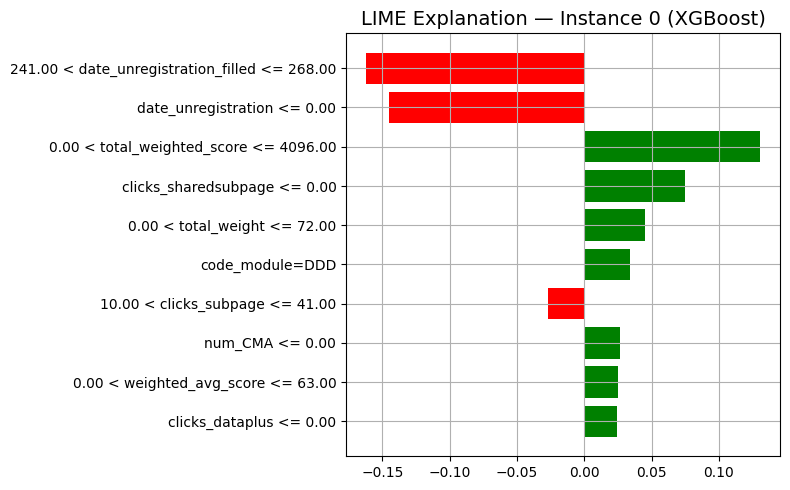

In [ ]:
# ============================================================
# Explain a single instance with LIME
# ============================================================

instance_idx = 0   # choose any row index from X_test

x_instance = X_test.iloc[instance_idx].copy()
x_instance_enc = x_instance.copy()

# Encode categorical fields for this instance
for col in cat_cols:
    val = str(x_instance_enc[col])
    x_instance_enc[col] = cat_to_int[col].get(val, 0)

print(f"\nExplaining test instance index: {instance_idx}")
print("True label     :", y_test.iloc[instance_idx])
print("Predicted label:", best_pipeline.predict(x_instance.to_frame().T)[0])

lime_exp = lime_explainer.explain_instance(
    data_row=x_instance_enc.values,
    predict_fn=pipeline_predict_proba_lime,
    num_features=10,
    top_labels=1
)

# Pick whichever label LIME has stored
label_to_use = lime_exp.available_labels()[0]

print("\nLIME feature contributions (feature, weight):")
for feat, val in lime_exp.as_list(label=label_to_use):
    print(f"  {feat:35s} {val: .4f}")

fig = lime_exp.as_pyplot_figure(label=label_to_use)
plt.title(f"LIME Explanation — Instance {instance_idx} ({best_model_name})", fontsize=14)
plt.tight_layout()
plt.show()



========== LIME for test index 0 ==========
True label     : 0
Predicted label: 0
Top contributions (feature, weight):
  241.00 < date_unregistration_filled <= 268.00 -0.1461
  date_unregistration <= 0.00         -0.1413
  0.00 < total_weighted_score <= 4096.00  0.1409
  0.00 < total_weight <= 72.00         0.0515
  num_CMA <= 0.00                      0.0445
  code_module=DDD                      0.0398
  1.00 < num_TMA <= 3.00               0.0217
  clicks_resource <= 5.00              0.0204
  clicks_dataplus <= 0.00              0.0185
  1.00 < num_assessments <= 5.00       0.0170


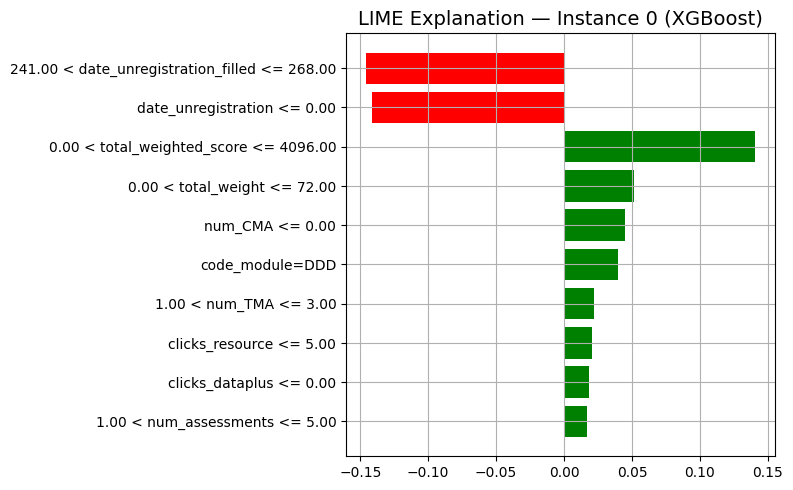


========== LIME for test index 10 ==========
True label     : 1
Predicted label: 1
Top contributions (feature, weight):
  date_unregistration <= 0.00          0.1576
  241.00 < date_unregistration_filled <= 268.00  0.1385
  63.00 < weighted_avg_score <= 78.07  0.0632
  clicks_sharedsubpage <= 0.00        -0.0470
  code_module=AAA                      0.0327
  num_CMA <= 0.00                     -0.0315
  4096.00 < total_weighted_score <= 8071.75  0.0284
  region=Yorkshire Region             -0.0283
  72.00 < total_weight <= 100.00       0.0274
  clicks_dataplus > 0.00               0.0261


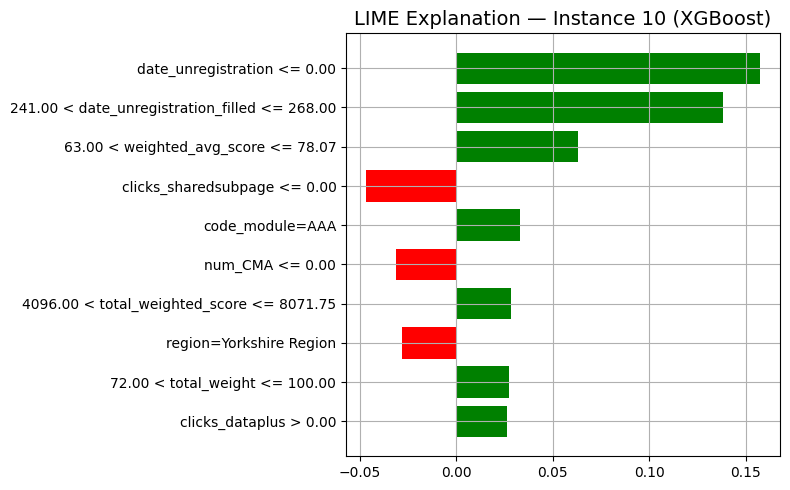


========== LIME for test index 50 ==========
True label     : 0
Predicted label: 0
Top contributions (feature, weight):
  date_unregistration <= 0.00         -0.1398
  total_weighted_score <= 0.00         0.1380
  241.00 < date_unregistration_filled <= 268.00 -0.1360
  weighted_avg_score <= 0.00           0.1112
  days_active <= 11.00                 0.0610
  num_TMA <= 1.00                     -0.0443
  clicks_sharedsubpage <= 0.00        -0.0437
  num_resources <= 19.00               0.0420
  num_CMA <= 0.00                      0.0406
  num_assessments <= 1.00              0.0392


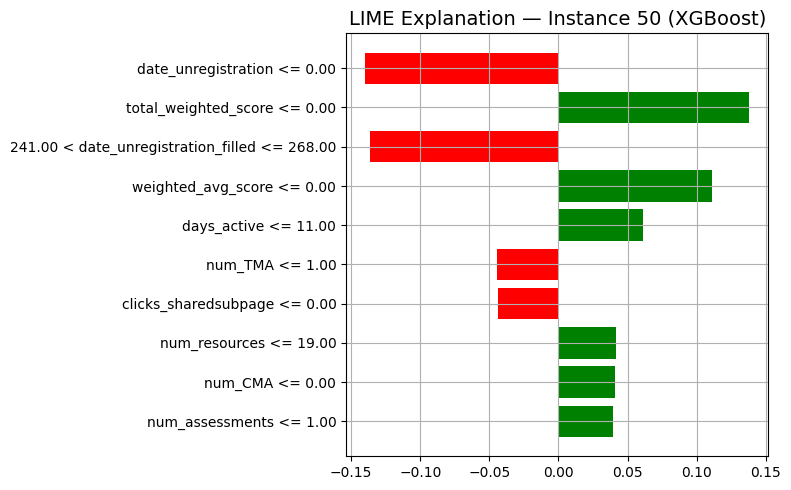

In [ ]:
# ============================================================
# LIME explanations for multiple key cases
# ============================================================

indices_to_explain = [0, 10, 50]  # or your Correct_Successful / Correct_At-Risk / Misclassified indices

for idx in indices_to_explain:
    x_i = X_test.iloc[idx].copy()
    x_i_enc = x_i.copy()

    for col in cat_cols:
        val = str(x_i_enc[col])
        x_i_enc[col] = cat_to_int[col].get(val, 0)

    exp_i = lime_explainer.explain_instance(
        data_row=x_i_enc.values,
        predict_fn=pipeline_predict_proba_lime,
        num_features=10,
        top_labels=1
    )

    label_to_use = exp_i.available_labels()[0]

    print(f"\n========== LIME for test index {idx} ==========")
    print("True label     :", y_test.iloc[idx])
    print("Predicted label:", best_pipeline.predict(x_i.to_frame().T)[0])
    print("Top contributions (feature, weight):")
    for feat, val in exp_i.as_list(label=label_to_use):
        print(f"  {feat:35s} {val: .4f}")

    fig = exp_i.as_pyplot_figure(label=label_to_use)
    plt.title(f"LIME Explanation — Instance {idx} ({best_model_name})", fontsize=14)
    plt.tight_layout()
    plt.show()


In [ ]:
from sklearn.metrics import (
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    auc,
    precision_recall_curve
)

# Assume your models dict already includes the ensemble, e.g.:
# models = {
#   "LogisticRegression": ...,
#   "RandomForest": ...,
#   "XGBoost": ...,
#   "MLP": ...,
#   "Bagging": bagging_clf   # or "Ensemble": ensemble_clf
# }

test_results = {}  # store predictions, probs, metrics per model

for name, clf in models.items():
    print(f"\n=== Fitting and evaluating {name} on test set ===")

    pipe = ImbPipeline(steps=[
        ("preprocess", preprocessor),
        ("smote", SMOTE(random_state=RANDOM_STATE)),
        ("model", clf)
    ])

    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]

    cm = confusion_matrix(y_test, y_pred)

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_auc = auc(fpr, tpr)

    prec, rec, _ = precision_recall_curve(y_test, y_prob)

    test_results[name] = {
        "pipeline": pipe,
        "y_pred": y_pred,
        "y_prob": y_prob,
        "cm": cm,
        "fpr": fpr,
        "tpr": tpr,
        "roc_auc": roc_auc,
        "prec": prec,
        "rec": rec
    }



=== Fitting and evaluating LogisticRegression on test set ===

=== Fitting and evaluating RandomForest on test set ===

=== Fitting and evaluating XGBoost on test set ===

=== Fitting and evaluating MLP on test set ===


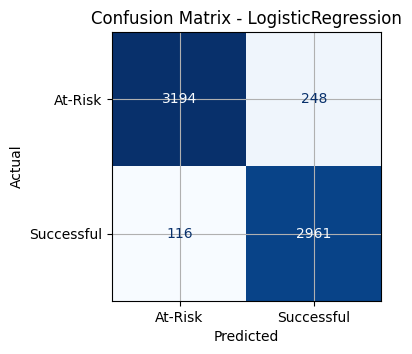

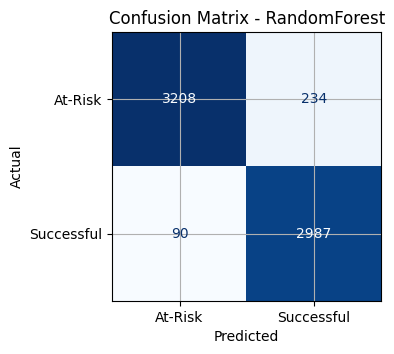

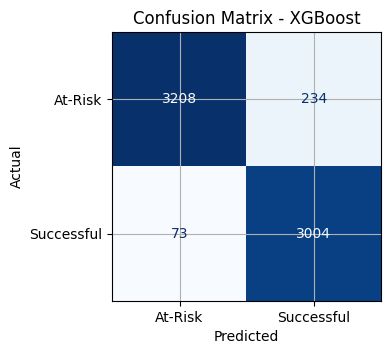

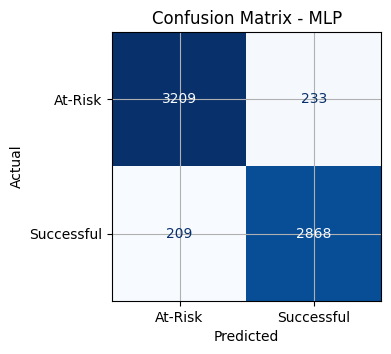

In [ ]:
# ============================================================
# Confusion Matrix for each model (Test Set)
# ============================================================

for name, res in test_results.items():
    cm = res["cm"]
    disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["At-Risk", "Successful"])

    fig, ax = plt.subplots(figsize=(4, 4))
    disp.plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.show()


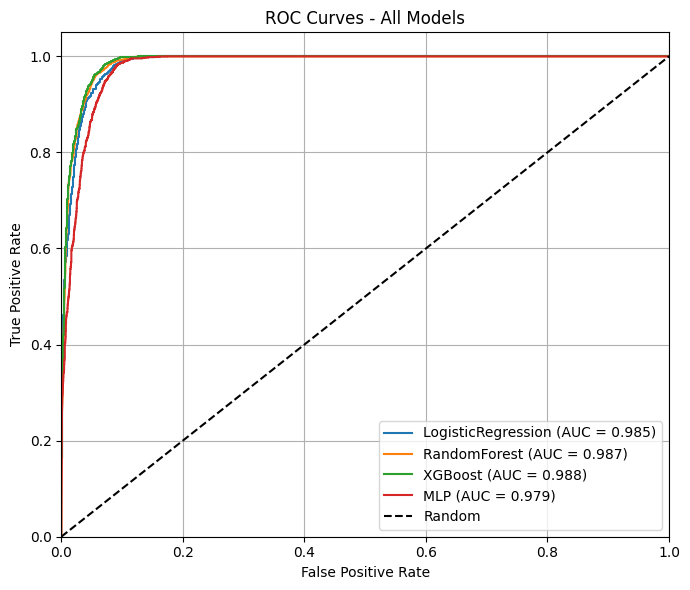

In [ ]:
# ============================================================
# ROC Curves for all models (Test Set)
# ============================================================

plt.figure(figsize=(7, 6))

for name, res in test_results.items():
    fpr = res["fpr"]
    tpr = res["tpr"]
    roc_auc = res["roc_auc"]
    plt.plot(fpr, tpr, label=f"{name} (AUC = {roc_auc:.3f})")

plt.plot([0, 1], [0, 1], "k--", label="Random")
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Models")
plt.legend(loc="lower right")
plt.tight_layout()
plt.show()


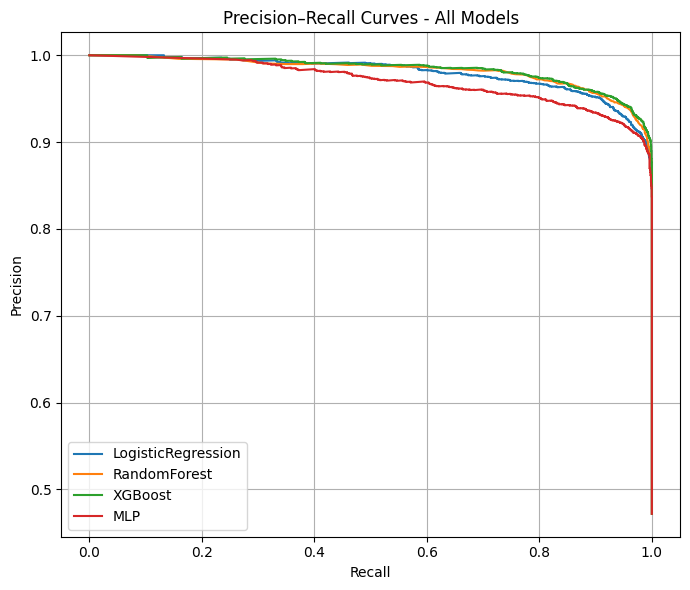

In [ ]:
# ============================================================
# Precision-Recall Curves for all models (Test Set)
# ============================================================

plt.figure(figsize=(7, 6))

for name, res in test_results.items():
    prec = res["prec"]
    rec = res["rec"]
    plt.plot(rec, prec, label=name)

plt.xlabel("Recall")
plt.ylabel("Precision")
plt.title("Precision–Recall Curves - All Models")
plt.legend(loc="lower left")
plt.tight_layout()
plt.show()


In [ ]:
# ============================================================
# Metric comparison (Accuracy, F1, ROC-AUC) per model
# ============================================================

metrics_summary = []

for name, res in test_results.items():
    y_pred = res["y_pred"]
    y_prob = res["y_prob"]

    acc = accuracy_score(y_test, y_pred)
    f1  = f1_score(y_test, y_pred)
    roc = res["roc_auc"]

    metrics_summary.append({
        "Model": name,
        "Accuracy": acc,
        "F1-Score": f1,
        "ROC-AUC": roc
    })

metrics_df = pd.DataFrame(metrics_summary)
metrics_df = metrics_df.sort_values(by="ROC-AUC", ascending=False)
print(metrics_df)


                Model  Accuracy  F1-Score   ROC-AUC
2             XGBoost  0.952907  0.951386  0.988286
1        RandomForest  0.950299  0.948555  0.987342
0  LogisticRegression  0.944163  0.942094  0.985295
3                 MLP  0.932198  0.928456  0.978984


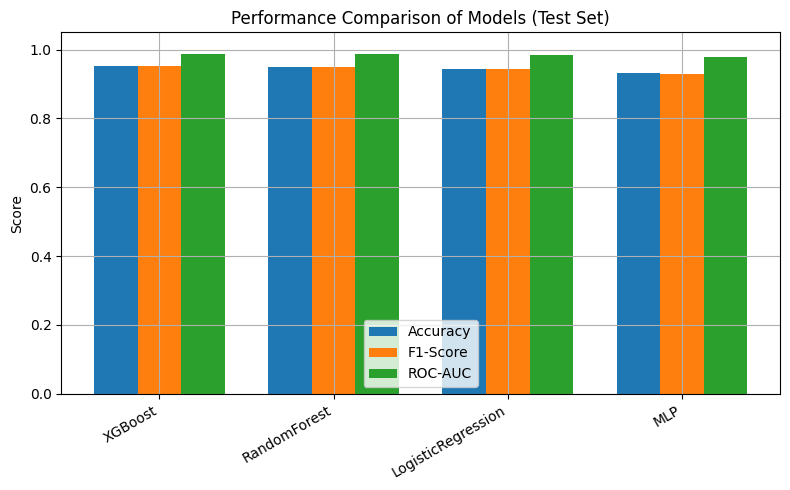

In [ ]:
fig, ax = plt.subplots(figsize=(8, 5))
x = np.arange(len(metrics_df))
width = 0.25

ax.bar(x - width, metrics_df["Accuracy"], width, label="Accuracy")
ax.bar(x,         metrics_df["F1-Score"], width, label="F1-Score")
ax.bar(x + width, metrics_df["ROC-AUC"],  width, label="ROC-AUC")

ax.set_xticks(x)
ax.set_xticklabels(metrics_df["Model"], rotation=30, ha="right")
ax.set_ylabel("Score")
ax.set_ylim(0.0, 1.05)
ax.set_title("Performance Comparison of Models (Test Set)")
ax.legend()
plt.tight_layout()
plt.show()


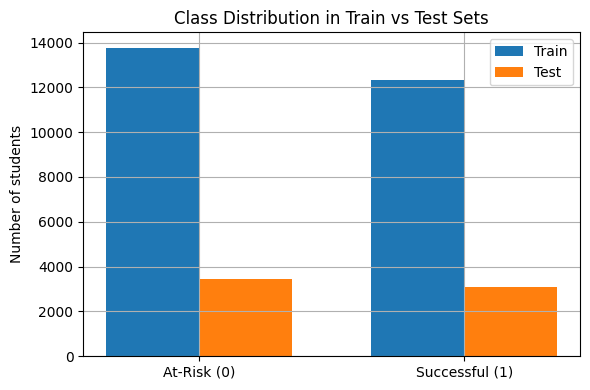

Train counts:
 passed
0    13766
1    12308
Name: count, dtype: int64

Test counts:
 passed
0    3442
1    3077
Name: count, dtype: int64


In [ ]:
# ============================================================
# Class balance bar plot for y_train vs y_test
# ============================================================

train_counts = y_train.value_counts().sort_index()
test_counts  = y_test.value_counts().sort_index()

labels = ["At-Risk (0)", "Successful (1)"]
x = np.arange(len(labels))
width = 0.35

fig, ax = plt.subplots(figsize=(6, 4))
ax.bar(x - width/2, train_counts.values, width, label="Train")
ax.bar(x + width/2, test_counts.values,  width, label="Test")

ax.set_xticks(x)
ax.set_xticklabels(labels)
ax.set_ylabel("Number of students")
ax.set_title("Class Distribution in Train vs Test Sets")
ax.legend()
plt.tight_layout()
plt.show()

print("Train counts:\n", train_counts)
print("\nTest counts:\n", test_counts)


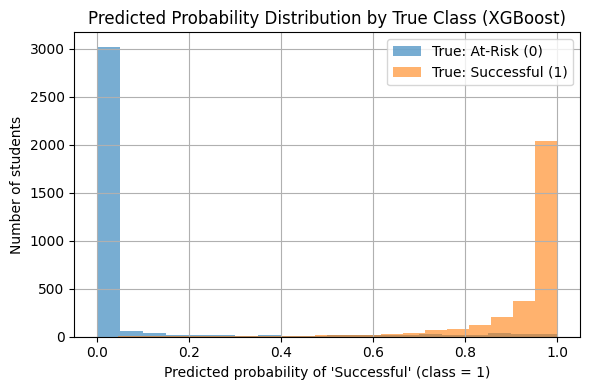

In [ ]:
# ============================================================
# Histogram of predicted probabilities per class (Best Model)
# ============================================================

best_name = best_model_name          # e.g. "XGBoost" or "Ensemble"
y_prob = test_results[best_name]["y_prob"]
y_pred = test_results[best_name]["y_pred"]   # not strictly needed here
y_true = y_test.values

fig, ax = plt.subplots(figsize=(6, 4))

# Probabilities for each true class
probs_class0 = y_prob[y_true == 0]
probs_class1 = y_prob[y_true == 1]

ax.hist(probs_class0, bins=20, alpha=0.6, density=False, label="True: At-Risk (0)")
ax.hist(probs_class1, bins=20, alpha=0.6, density=False, label="True: Successful (1)")

ax.set_xlabel("Predicted probability of 'Successful' (class = 1)")
ax.set_ylabel("Number of students")
ax.set_title(f"Predicted Probability Distribution by True Class ({best_name})")
ax.legend()
plt.tight_layout()
plt.show()


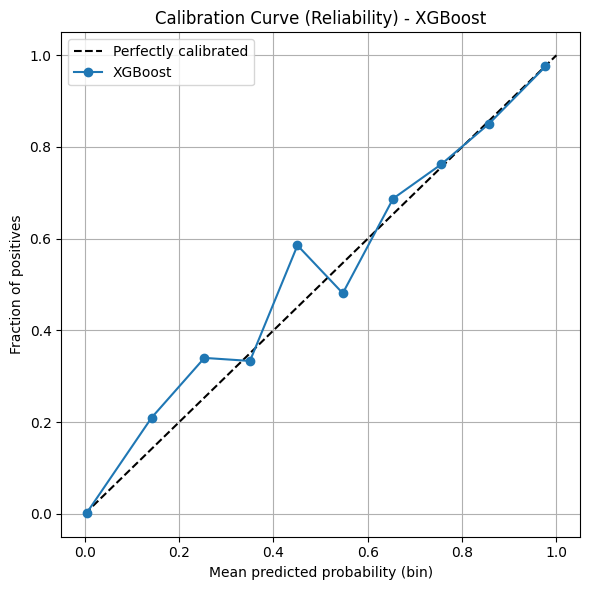

In [ ]:
# ============================================================
# Calibration curve for Best Model
# ============================================================

from sklearn.calibration import calibration_curve

best_name = best_model_name
y_prob = test_results[best_name]["y_prob"]
y_true = y_test.values

prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="uniform")

fig, ax = plt.subplots(figsize=(6, 6))

# Perfect calibration line
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")

# Model calibration
ax.plot(prob_pred, prob_true, marker="o", linewidth=1.5, label=f"{best_name}")

ax.set_xlabel("Mean predicted probability (bin)")
ax.set_ylabel("Fraction of positives")
ax.set_title(f"Calibration Curve (Reliability) - {best_name}")
ax.legend()
plt.tight_layout()
plt.show()


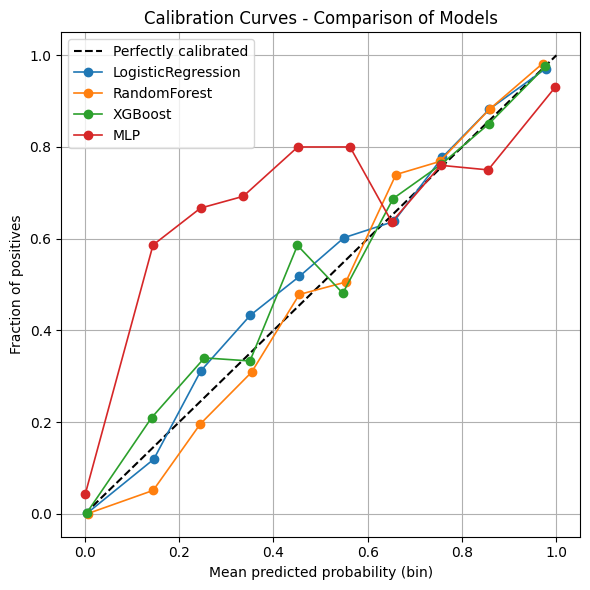

In [ ]:
# ============================================================
# Calibration curves for multiple models
# ============================================================

from sklearn.calibration import calibration_curve

models_to_plot = ["LogisticRegression", "RandomForest", "XGBoost", "MLP", "Bagging"]  # adjust names

fig, ax = plt.subplots(figsize=(6, 6))

# Perfect line
ax.plot([0, 1], [0, 1], "k--", label="Perfectly calibrated")

for name in models_to_plot:
    if name not in test_results:
        continue
    y_prob = test_results[name]["y_prob"]
    y_true = y_test.values

    prob_true, prob_pred = calibration_curve(y_true, y_prob, n_bins=10, strategy="uniform")
    ax.plot(prob_pred, prob_true, marker="o", linewidth=1.2, label=name)

ax.set_xlabel("Mean predicted probability (bin)")
ax.set_ylabel("Fraction of positives")
ax.set_title("Calibration Curves - Comparison of Models")
ax.legend()
plt.tight_layout()
plt.show()
